# Lab 7: Go-to-goal, digits 48

Student ID: **240048**

I compared the simulator run and the real robot run against the ideal shape of "48".

## 1. Load the logs

Positions are converted to cm and time to seconds.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

files = {'Simulator': 'odometry_data_sim.txt', 'Real': 'odometry_data_real.txt'}
if not all(os.path.exists(f) for f in files.values()):
    from google.colab import files as colab_files
    colab_files.upload()

runs = {}
for name, file in files.items():
    data = np.loadtxt(file, delimiter=',')
    runs[name] = {'xy': data[:, :2] * 100, 't': (data[:, 2] - data[0, 2]) / 1000}
    print(f"{name}: {len(data)} samples, {runs[name]['t'][-1]:.1f} s")

Simulator: 3200 samples, 64.0 s
Real: 468 samples, 53.6 s


## 2. Ideal path

The 4 is 24 cm wide and 60 cm tall. The 8 is two circles of radius 15 cm, each split into 32 short segments. The robot starts at (0, 0) and should finish in the middle of the 8, at **(46.5, -30) cm**.

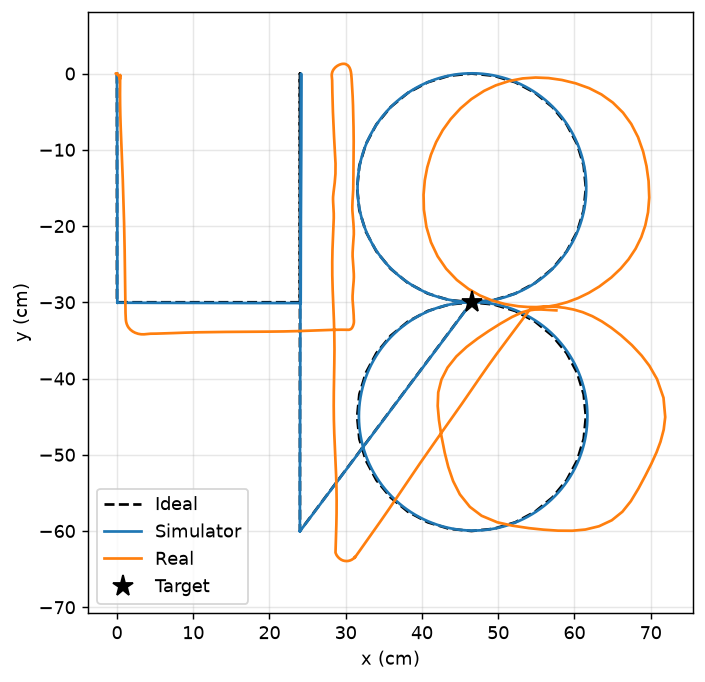

In [2]:
def circle(cy, start, turn):
    a = start + turn * np.linspace(0, 2 * np.pi, 33)[1:]
    return np.column_stack([46.5 + 15 * np.cos(a), cy + 15 * np.sin(a)])

W = np.vstack([[[0, 0], [0, -30], [24, -30], [24, 0], [24, -60], [46.5, -30]],
               circle(-15, -np.pi / 2, 1),     # top loop, counter-clockwise
               circle(-45, np.pi / 2, -1)])    # bottom loop, clockwise
X_ref, Y_ref = W[:, 0], W[:, 1]
target = W[-1]

plt.figure(figsize=(6, 6))
plt.plot(X_ref, Y_ref, 'k--', label='Ideal')
for name, run in runs.items():
    plt.plot(*run['xy'].T, label=name)
plt.plot(*target, 'k*', markersize=12, label='Target')
plt.xlabel('x (cm)'); plt.ylabel('y (cm)')
plt.axis('equal'); plt.grid(alpha=0.3); plt.legend()
plt.show()

## 3. Errors along the path

Each sample is matched to the current segment or the next one, never further ahead. It moves on when the next segment is closer, or when the robot is within 0.5 cm of the end of the current one. This matters on the 4, where the robot drives up and then back down the same line.

- `distance`: signed sideways offset from the segment, positive = left of the path.
- `courseAngle`: segment direction minus direction of motion, wrapped to ±180°. Samples where the robot barely moved are skipped.

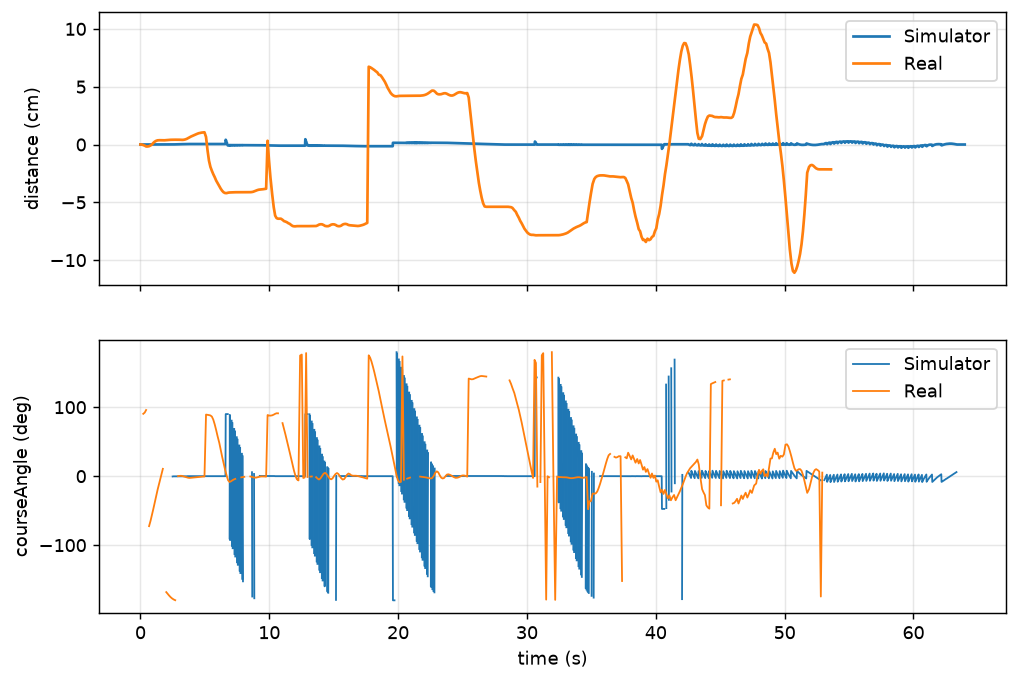

In [3]:
seg = np.diff(W, axis=0)
length = np.linalg.norm(seg, axis=1)
course = np.arctan2(seg[:, 1], seg[:, 0])

def project(p, i):
    """Position along segment i (0..1) and distance to it."""
    u = np.clip((p - W[i]) @ seg[i] / length[i]**2, 0, 1)
    return u, np.linalg.norm(p - W[i] - u * seg[i])

def assign_segments(xy):
    i, result = 0, []
    for p in xy:
        if i < len(seg) - 1:
            u, d_now = project(p, i)
            _, d_next = project(p, i + 1)
            near_end = (1 - u) * length[i] < 0.5
            if near_end or (u > 0.5 and d_next < d_now - 1e-8):
                i += 1
        result.append(i)
    return np.array(result)

for run in runs.values():
    xy = run['xy']
    i = assign_segments(xy)
    dx, dy = (xy - W[i]).T
    run['segment'] = i
    run['distance'] = -dx * np.sin(course[i]) + dy * np.cos(course[i])

    step = np.diff(xy, axis=0)
    error = course[i][1:] - np.arctan2(step[:, 1], step[:, 0])
    error = np.degrees((error + np.pi) % (2 * np.pi) - np.pi)
    error[np.linalg.norm(step, axis=1) < 0.02] = np.nan
    run['courseAngle'] = error

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for name, run in runs.items():
    ax[0].plot(run['t'], run['distance'], label=name)
    ax[1].plot(run['t'][1:], run['courseAngle'], label=name, linewidth=1)
ax[0].set_ylabel('distance (cm)')
ax[1].set_ylabel('courseAngle (deg)')
ax[1].set_xlabel('time (s)')
for a in ax:
    a.grid(alpha=0.3); a.legend()
plt.show()

## 4. Closest approach to each waypoint

Points 0-5 are the 4 and the move to the 8, 6-37 the top loop, 38-69 the bottom loop.

In [5]:
miss = [np.linalg.norm(r['xy'][:, None] - W[None], axis=2).min(axis=0) for r in runs.values()]

print(f"{'point':>5}{'x':>8}{'y':>8}{'sim':>8}{'real':>8}   (cm)")
for k, (x, y) in enumerate(W):
    print(f'{k:>5}{x:>8.1f}{y:>8.1f}{miss[0][k]:>8.2f}{miss[1][k]:>8.2f}')

point       x       y     sim    real   (cm)
    0     0.0     0.0    0.00    0.00
    1     0.0   -30.0    0.05    1.21
    2    24.0   -30.0    0.06    3.80
    3    24.0     0.0    0.14    4.18
    4    24.0   -60.0    0.02    4.75
    5    46.5   -30.0    0.02    1.42
    6    49.4   -29.7    0.02    0.24
    7    52.2   -28.9    0.08    1.70
    8    54.8   -27.5    0.06    3.16
    9    57.1   -25.6    0.01    4.79
   10    59.0   -23.3    0.06    6.17
   11    60.4   -20.7    0.11    7.49
   12    61.2   -17.9    0.05    8.32
   13    61.5   -15.0    0.05    8.27
   14    61.2   -12.1    0.07    8.01
   15    60.4    -9.3    0.11    7.18
   16    59.0    -6.7    0.08    5.51
   17    57.1    -4.4    0.06    3.76
   18    54.8    -2.5    0.09    2.01
   19    52.2    -1.1    0.11    0.83
   20    49.4    -0.3    0.06    1.29
   21    46.5     0.0    0.04    2.81
   22    43.6    -0.3    0.09    4.22
   23    40.8    -1.1    0.07    5.50
   24    38.2    -2.5    0.01    6.58
   25

## 5. Physical endpoint

The measured final position was **(62.8, -34.9) cm**, using the same origin and axes as the trajectory plot. Below I compare it with the target and the final odometry estimate.


In [6]:
measured_end = (62.8, -34.9)  # cm

ends = {'Target': target, 'Simulator end': runs['Simulator']['xy'][-1], 'Real odometry end': runs['Real']['xy'][-1]}
if measured_end is not None:
    ends['Measured end'] = np.array(measured_end)

for label, p in ends.items():
    print(f'{label:<18}({p[0]:6.1f}, {p[1]:6.1f}) cm   {np.linalg.norm(p - target):5.1f} cm from target')
if measured_end is not None:
    print(f"Odometry vs tape: {np.linalg.norm(ends['Measured end'] - ends['Real odometry end']):.1f} cm")

Target            (  46.5,  -30.0) cm     0.0 cm from target
Simulator end     (  46.8,  -30.0) cm     0.3 cm from target
Real odometry end (  57.6,  -31.1) cm    11.2 cm from target
Measured end      (  62.8,  -34.9) cm    17.0 cm from target
Odometry vs tape: 6.4 cm


## 6. Discussion

The simulator stays within 0.5 cm sideways of the ideal path, while the real odometry shows drift through the 4 that carries into the 8. The real trace overshoots the lower corners, with the largest sideways error (11.1 cm) on the bottom loop, and direction estimates peak around turns. The measured endpoint is 17.0 cm from the target, compared with 11.2 cm from the real odometry. The 6.4 cm gap between measurement and odometry indicates a localization discrepancy, in addition to the tracking error visible in odometry. Minimum motor commands, stopping behaviour and turn response may contribute to the tracking error, but these runs cannot identify a single gain as the cause; the recorded controller did not use a waypoint acceptance radius.
